## Downstream Analysis

Note: Please run the notebook Patch_PatchEmbeddings_Unimodel.ipynb before this notebook, as it is responsible for creating the patches, patch embeddings and metadata needed for this notebook.

**PCA (Principal Component Analysis)**:  
We run PCA with a reduction to 50 components (UNI model has 1536 features).  
Results are stored in adata.obsm["X_pca"] (PCA components (n x 50)).

**UMAP (Uniform Manifold Approximation and Projection for Dimension Reduction)**:  


**Leiden Clustering**:

In [1]:
import anndata as ad
from tqdm import tqdm
import scanpy as sc

adata = sc.read("metadata/WSI_patch_embeddings.h5ad")

print(adata.obs["Slide_ID"].unique())

['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']
Categories (5, object): ['CRC_P1', 'CRC_P2', 'CRC_P5', 'Normal_P3', 'Normal_P5']


In [2]:
patch_base_folder = "patches"
leiden_res = [0.2, 0.5, 1.0, 2.0] # set the resolutions you want to use for leiden clustering

In [3]:
# PCA
sc.pp.pca(adata, n_comps=50)
sc.pp.neighbors(adata, use_rep="X_pca")

/home/charlottewolf/miniconda3/envs/uni/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# UMAP
sc.tl.umap(adata)

KeyboardInterrupt: 

In [ ]:
# Leiden Clustering
def run_leiden(adata, leiden_res):
    for res in leiden_res:
        key = f"leiden_{res}"
        sc.tl.leiden(adata, resolution=res, key_added=key)

run_leiden(adata, leiden_res)

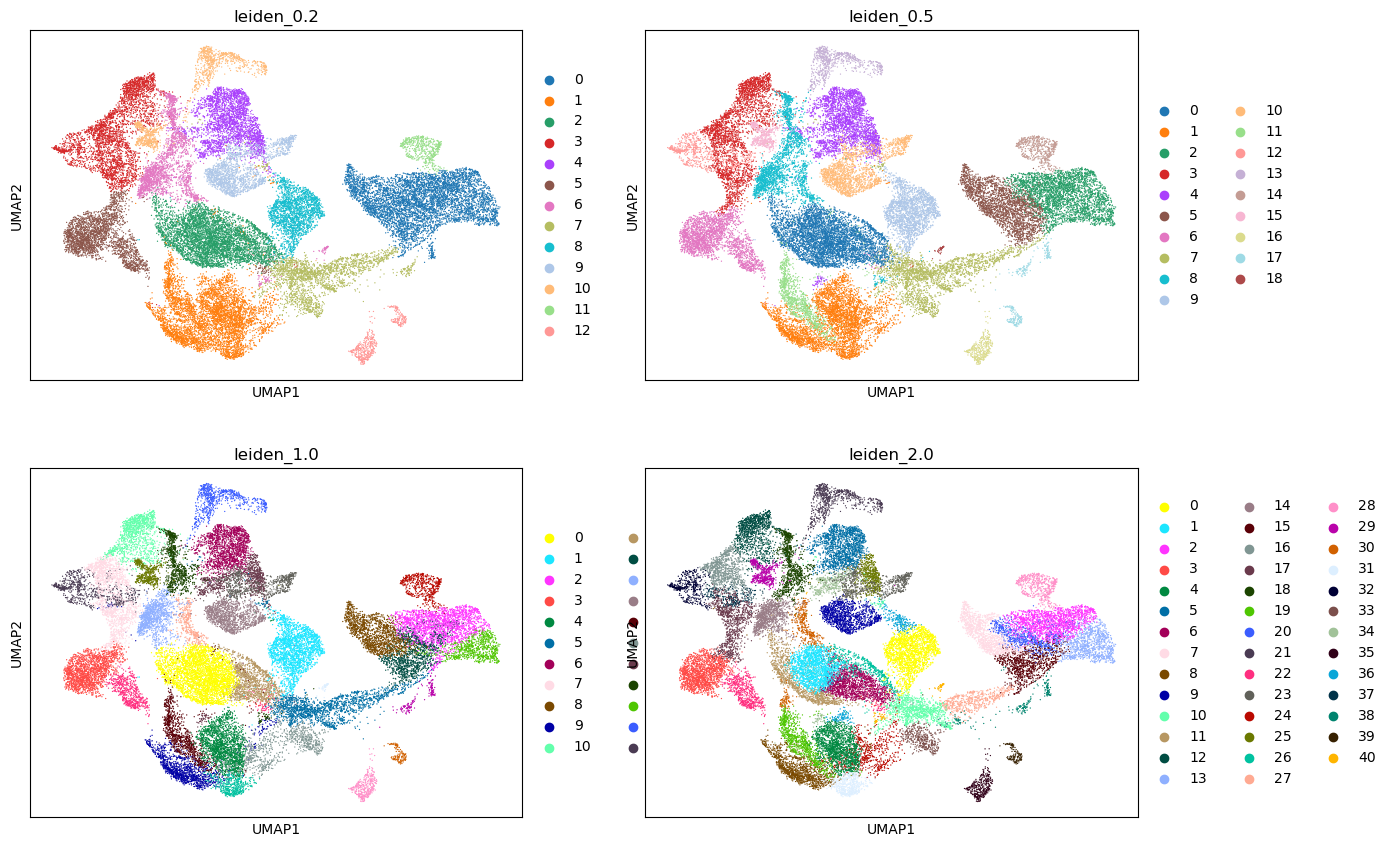

In [38]:
sc.pl.umap(adata, color=["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"], ncols=2)

## Plotting the Clusters with examplary patches
We can use these cluster patches to filter out clusters that combine the background and save foreground images to a new adata object.

In [43]:
chosen_resolution = 0.5 # Choose the resolution you want to use for filtering

/tmp/ipykernel_7300/1761976139.py:39: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]  # Get Sample ID
/tmp/ipykernel_7300/1761976139.py:40: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]  # Get Patch file name


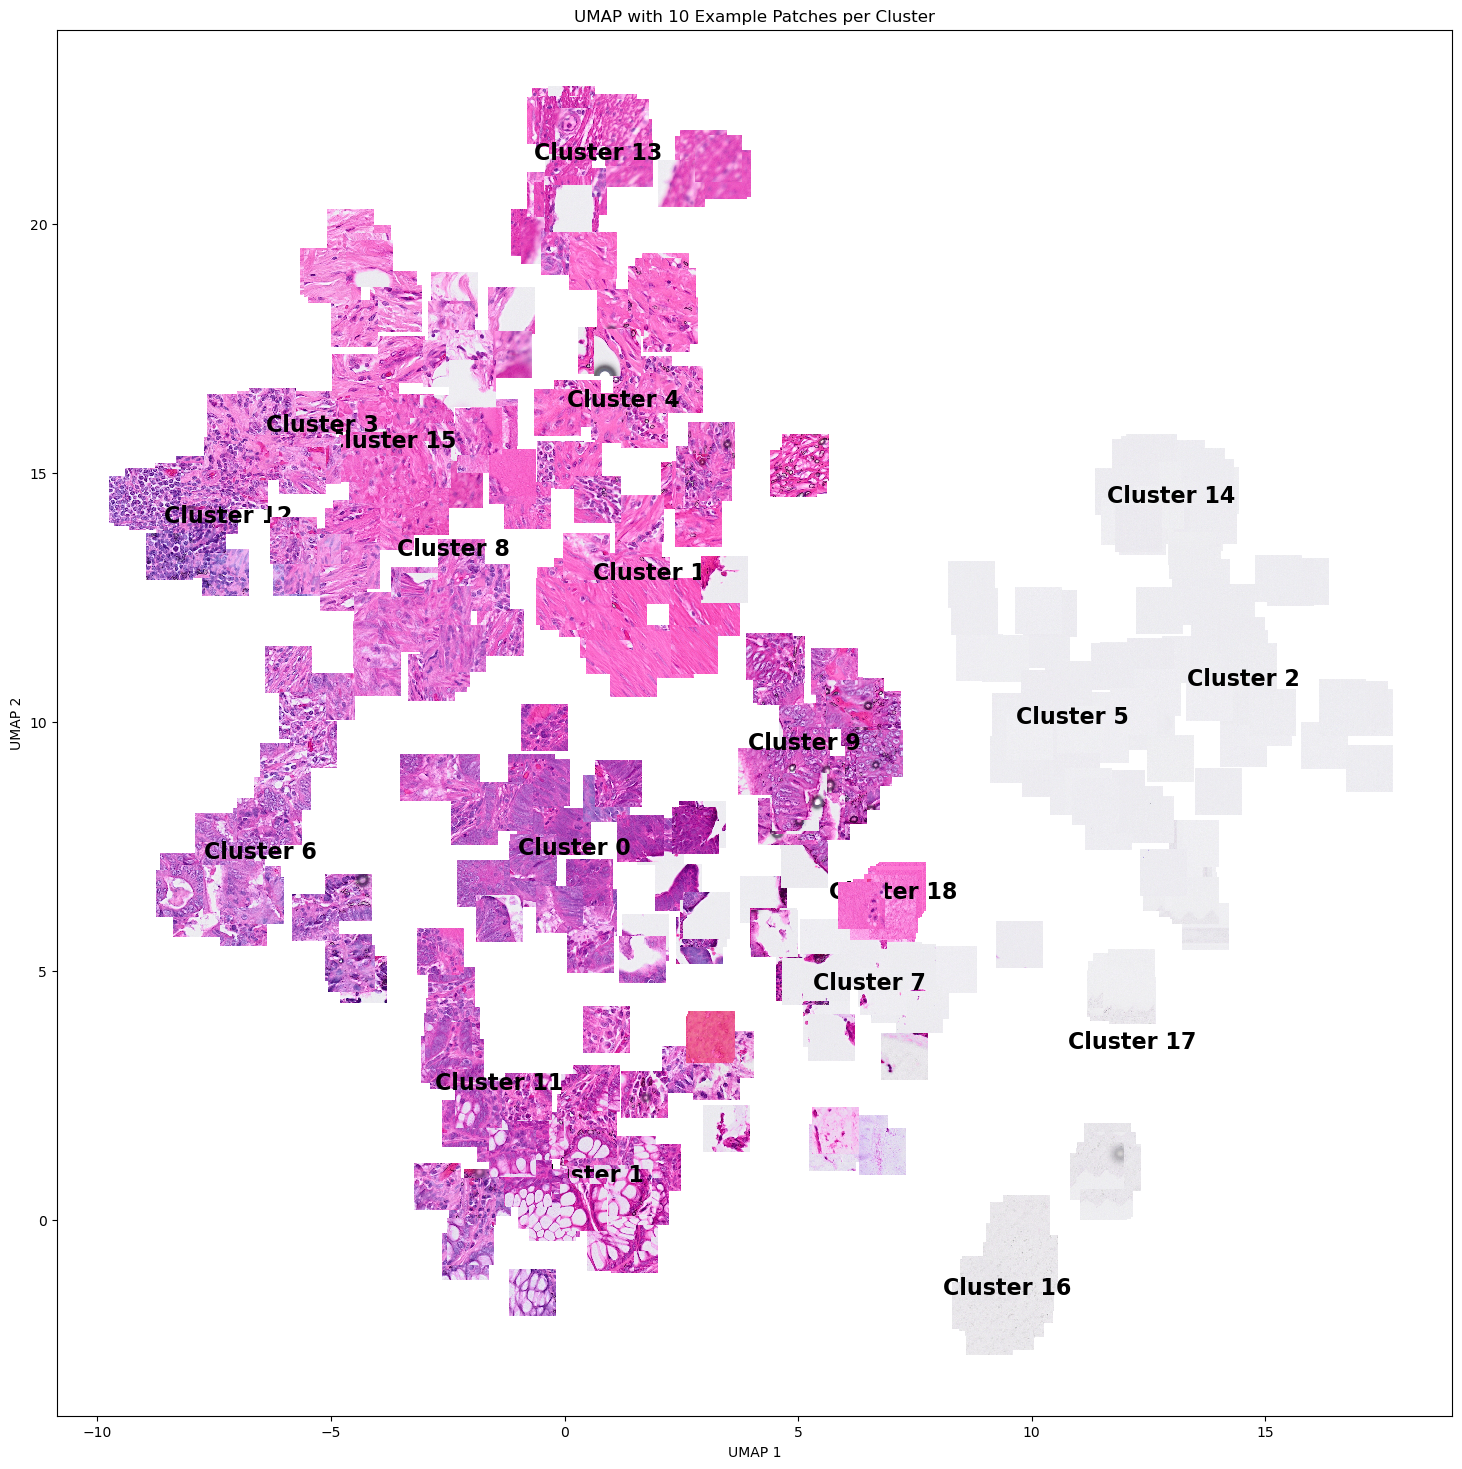

In [ ]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random


def plot_patches(adata, res, patch_base_folder="patches"):

    umap_coords = adata.obsm["X_umap"]
    clusters = adata.obs[f"leiden_{res}"].astype(str)  # Convert Leiden clusters to strings
    sample_ids = adata.obs["Slide_ID"].astype(str)  # Get patient/sample IDs
    patch_ids = adata.obs["Patch_ID"].astype(str)  # Get patch file names


    def getImage(path, zoom=0.15):  # Adjust zoom level for patch size
        return OffsetImage(plt.imread(path), zoom=zoom)


    fig, ax = plt.subplots(figsize=(18, 18))
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")


    for cluster in sorted(clusters.unique()):

        cluster_indices = np.where(clusters == cluster)[0]
        if len(cluster_indices) == 0:
            continue

        selected_indices = random.sample(list(cluster_indices), min(30, len(cluster_indices)))

    
        for i in selected_indices:
            x0, y0 = umap_coords[i]  # Get UMAP position
            sample_id = sample_ids[i]  # Get Sample ID
            patch_id = patch_ids[i]  # Get Patch file name

            patch_folder = os.path.join(patch_base_folder, sample_id)
            patch_path = os.path.join(patch_folder, patch_id)

            if not os.path.exists(patch_path):
                print(f"Warning: Missing patch {patch_path}")
                continue


            ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
            ax.add_artist(ab)


        avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
        ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")


    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title("UMAP with 10 Example Patches per Cluster")
    #fig.savefig('Umap_patches.pdf')
plot_patches(adata, chosen_resolution, patch_base_folder)


## Filtering clusters with no tisssue 
In the following, we filter out clusters that have no tissue in it.
Note, that there can be clusters where there seems to be some patches with and without tissues.  
We then re-run PCA, the neighbor graph, UMAP and leiden and store the new filtered AnnData Object in the metadata folder as "filtered_WSI_patch_embeddings.h5ad".

Use the following cell to filter out any cluster that only has background information. Adapt "keep_clusters" to the clusters you want to keep before running the cell.    
This also stores the unfiltered patch embeddings in the patch folder for each person. 

In [49]:
people = adata.obs["Slide_ID"].unique()
remove_clusters = ['2', '5', '14', '16', '17'] # Adapt based on the clusters you want to remove. See plot above.

for person in people:
    patient_adata = adata[adata.obs["Slide_ID"] == person].copy()
    if not os.path.exists(f"{patch_base_folder}/{person}"):
        os.makedirs(f"{patch_base_folder}/{person}")
    patient_adata.write(f"{patch_base_folder}/{person}/unfiltered_patch_embeddings.h5ad")
adata_filter=adata[~adata.obs[f"leiden_{chosen_resolution}"].isin(remove_clusters)].copy()
adata_filter.write("metadata/filtered_WSI_patch_embeddings.h5ad")

In [19]:
adata_filter

AnnData object with n_obs × n_vars = 28245 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0'
    uns: 'pca', 'neighbors', 'umap', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0', 'leiden_0.2_colors', 'leiden_0.5_colors', 'leiden_1.0_colors', 'leiden_2.0_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

Now we only plot clusters with tissue in it. 

/tmp/ipykernel_7300/3310215060.py:37: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sample_id = sample_ids[i]  # Get Sample ID
/tmp/ipykernel_7300/3310215060.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  patch_id = patch_ids[i]  # Get Patch file name


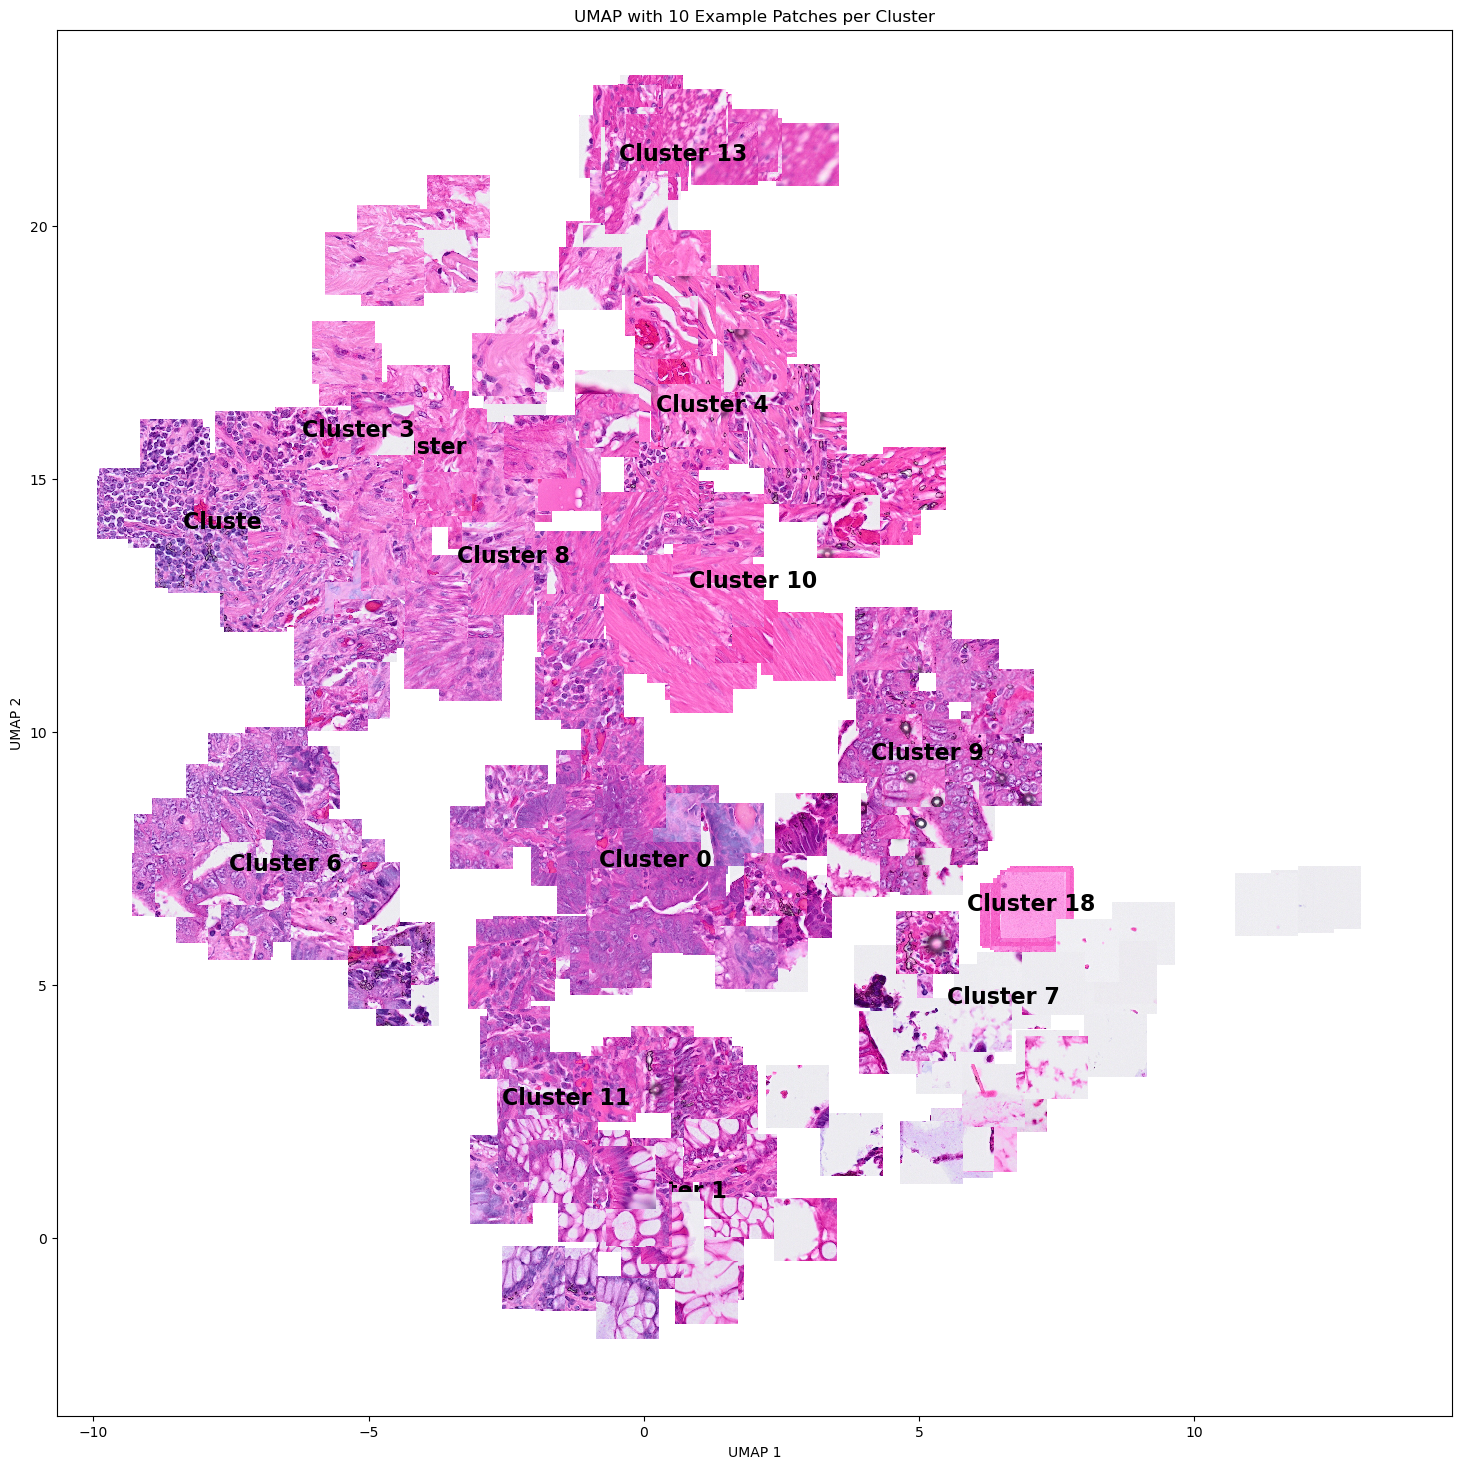

In [20]:
import os
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import seaborn as sns
import random


umap_coords = adata_filter.obsm["X_umap"]
clusters = adata_filter.obs[f"leiden_{chosen_resolution}"].astype(str)  # Convert Leiden clusters to strings
sample_ids = adata_filter.obs["Slide_ID"].astype(str)  # Get patient/sample IDs
patch_ids = adata_filter.obs["Patch_ID"].astype(str)  # Get patch file names


patch_base_folder = "patches"


def getImage(path, zoom=0.2):  # Adjust zoom level for patch size
    return OffsetImage(plt.imread(path), zoom=zoom)


fig, ax = plt.subplots(figsize=(18, 18))
ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="white", alpha=1, edgecolors="w", label="Cells")


for cluster in sorted(clusters.unique()):

    cluster_indices = np.where(clusters == cluster)[0]
    if len(cluster_indices) == 0:
        continue

    selected_indices = random.sample(list(cluster_indices), min(30, len(cluster_indices)))

 
    for i in selected_indices:
        x0, y0 = umap_coords[i]  # Get UMAP position
        sample_id = sample_ids[i]  # Get Sample ID
        patch_id = patch_ids[i]  # Get Patch file name

        patch_folder = os.path.join(patch_base_folder, sample_id)
        patch_path = os.path.join(patch_folder, patch_id)

        if not os.path.exists(patch_path):
            print(f"Warning: Missing patch {patch_path}")
            continue


        ab = AnnotationBbox(getImage(patch_path), (x0, y0), frameon=False, box_alignment=(0.5, 0.5), pad=0)
        ax.add_artist(ab)


    avg_x, avg_y = np.mean(umap_coords[cluster_indices], axis=0)
    ax.annotate(f"Cluster {cluster}", (avg_x, avg_y), fontsize=16, ha="center", color="black", weight="bold")


ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP with 10 Example Patches per Cluster")
fig.savefig('Umap_patches.pdf')

In [21]:
adata_filter

AnnData object with n_obs × n_vars = 28245 × 1536
    obs: 'Slide_ID', 'Patch_ID', 'X', 'Y', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0'
    uns: 'pca', 'neighbors', 'umap', 'leiden_0.2', 'leiden_0.5', 'leiden_1.0', 'leiden_2.0', 'leiden_0.2_colors', 'leiden_0.5_colors', 'leiden_1.0_colors', 'leiden_2.0_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

Perform Leiden again on filtered patch embeddings. 

In [ ]:
# Delete leiden columns
for res in leiden_res:
    if f"leiden_{res}" in adata_filter.obs:
        del adata_filter.obs[f"leiden_{res}"]
    if f"leiden_{res}" in adata_filter.uns:
        del adata_filter.uns[f"leiden_{res}"]


# Re-run PCA and leiden on filtered patch embeddings
sc.pp.pca(adata_filter, n_comps=50)
sc.pp.neighbors(adata, use_rep="X_pca")
sc.tl.umap(adata_filter)

run_leiden(adata_filter, leiden_res)

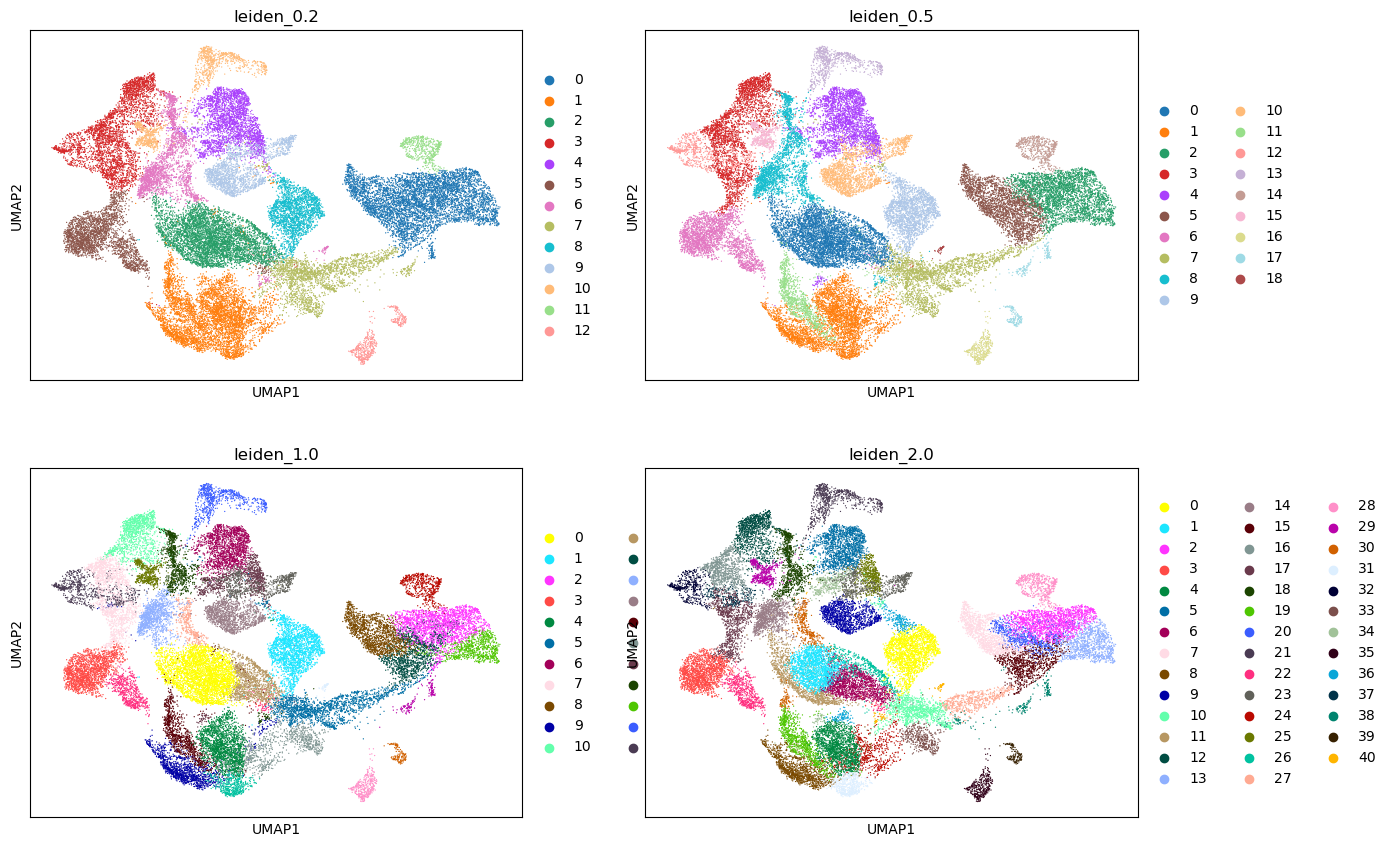

In [24]:
sc.pl.umap(adata, color=["leiden_0.2", "leiden_0.5", "leiden_1.0", "leiden_2.0"], ncols=2)

In [50]:
new_leiden_res = 0.5
plot_patches(adata_filter, new_leiden_res, patch_base_folder)

TypeError: plot_patches() takes 2 positional arguments but 3 were given